# BC카드 외국인 소비구조 기반 상권 진단 — 전체 분석 노트북

이 노트북은 BC 공모전 원데이터에서 출발해 다음 분석을 처음부터 끝까지 재현한다.

1. 데이터 구조 및 품질 EDA
2. 내국인 vs 외국인 업종 소비구조 차이(TVD) 계산
3. `Scale × TVD` 기반 Structure 4유형 분류
4. H1/H2 Structure 강건성 검증
5. CNT·ATV 기반 Momentum
6. 기간창(2개월/3개월) 강건성 기반 High/Medium/Low Confidence 산출
7. 법무부 등록외국인·행안부 주민등록인구 255개 지역 전체 결합
8. 외부검증 A: BC 외국인 소비규모와 등록외국인 분포의 수렴
9. 외부검증 B: TVD의 외적 타당성 — Pearson/Spearman, 삼분위, Mann–Whitney
10. 대표사례: 같은 외국인 소비 핵심지역도 구조는 다르다
11. 잔차 분석: 등록외국인 수로 설명되지 않는 외국인 카드소비
12. 한국관광공사 2026H1 방문자 데이터 결합과 External Context(정주우세·혼합·방문우세)
13. 최종 Action Matrix 생성
14. LLM Action Layer 제안
15. 최종 의사결정 프레임워크
16. 최종 결론

> 핵심 원칙: **데이터 → 검증된 라벨 → 근거 → Action** 순서로 의사결정을 구조화한다.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr, mannwhitneyu, kruskal
from sklearn.metrics import cohen_kappa_score
import statsmodels.api as sm

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')

BASE = Path('..')
RAW_PATH = BASE/'02_data/raw/ABP_CONTEST_DATA.csv'
MOJ_PATH = BASE/'02_data/external/MOJ_registered_foreigners_202606_255.csv'
POP_PATH = BASE/'02_data/external/MOIS_resident_population_202606_255.csv'

KTO_RAW_PATH = BASE/'02_data/external/KTO_visitors_2026H1_raw.csv'
EXT_JOINED_PATH = BASE/'02_data/external/external_validation_255_joined.csv'


# 모든 그래프에 적용되는 한글 폰트 설정 (Windows / macOS / Linux)
# 설치된 폰트를 우선 사용합니다. 없으면 Noto 공식 저장소에서 최초 1회 내려받습니다.
import matplotlib.font_manager as _fm
from matplotlib.ft2font import FT2Font as _FT2Font
import urllib.request as _urlrequest

def _configure_korean_font():
    _names = ("Malgun Gothic", "AppleGothic", "NanumGothic",
              "Noto Sans CJK KR", "Noto Sans KR", "Noto Sans CJK JP")
    _required = set(map(ord, "한글외국인소비구조거래건수전체비중개월정주방문객단가영암제주시등록"))

    def _register(_path):
        _path = Path(_path)
        if not _path.is_file():
            return None
        try:
            if not _required.issubset(_FT2Font(str(_path)).get_charmap()):
                return None
            _fm.fontManager.addfont(str(_path))
            return _fm.FontProperties(fname=str(_path)).get_name()
        except (OSError, RuntimeError, ValueError):
            return None

    # OS에 설치된 폰트 사용: 사용자 환경의 별도 폰트 설치를 최대한 피합니다.
    _entries = list(_fm.fontManager.ttflist)
    _selected = None
    for _name in _names:
        for _entry in _entries:
            if _entry.name == _name:
                _selected = _register(_entry.fname)
                if _selected:
                    break
        if _selected:
            break

    # 프로젝트 폰트 또는 이전 실행에서 저장된 폰트 사용
    _cache_font = Path.home() / ".cache" / "bc-analysis" / "fonts" / "NotoSansCJKkr-Regular.otf"
    if not _selected:
        for _path in (Path("fonts/NotoSansCJKkr-Regular.otf"),
                      Path("../fonts/NotoSansCJKkr-Regular.otf"), _cache_font):
            _selected = _register(_path)
            if _selected:
                break

    if not _selected:
        _url = ("https://raw.githubusercontent.com/notofonts/noto-cjk/main/"
                "Sans/OTF/Korean/NotoSansCJKkr-Regular.otf")
        _cache_font.parent.mkdir(parents=True, exist_ok=True)
        _temp_font = _cache_font.with_suffix(".download")
        try:
            with _urlrequest.urlopen(_url, timeout=30) as _response:
                _temp_font.write_bytes(_response.read())
            if not _required.issubset(_FT2Font(str(_temp_font)).get_charmap()):
                raise RuntimeError("내려받은 폰트의 한글 글리프를 확인할 수 없습니다.")
            _temp_font.replace(_cache_font)
            _selected = _register(_cache_font)
        except Exception as _error:
            _temp_font.unlink(missing_ok=True)
            raise RuntimeError(
                "한글 폰트를 찾지 못했습니다. 맑은 고딕/나눔고딕/Noto Sans CJK KR을 설치한 뒤 "
                "커널을 재시작하거나, NotoSansCJKkr-Regular.otf를 fonts 폴더에 넣어주세요. "
                "자동 다운로드를 사용할 때는 인터넷 연결이 필요합니다."
            ) from _error

    plt.rcParams.update({
        "font.family": [_selected],
        "axes.unicode_minus": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })
    print(f"그래프 한글 폰트: {_selected}")
    return _selected

KOREAN_FONT = _configure_korean_font()


그래프 한글 폰트: Noto Sans CJK KR


## 1. Raw data load & 기본 구조 확인

In [2]:
df = pd.read_csv(RAW_PATH)
print('shape:', df.shape)
print('months:', sorted(df['STRD_YYMM'].unique()))
print('SIDO:', df['SIDO_NM'].nunique(), '개')
print('업종:', df['TP_BUZ_NM'].nunique(), '개')
print('GENDER_CD:', sorted(df['GENDER_CD'].astype(str).unique()))
print('AGE_CD:', sorted(df['AGE_CD'].astype(str).unique()))
df.head()

shape: (242574, 9)
months: [np.int64(202601), np.int64(202602), np.int64(202603), np.int64(202604), np.int64(202605), np.int64(202606)]
SIDO: 17 개
업종: 11 개
GENDER_CD: ['1', '2', '3', 'x']
AGE_CD: ['1', '2', '3', '4', '5', '6', 'x']
Out[2]: 
   STRD_YYMM SIDO_NM  CCG_NM GENDER_CD AGE_CD  TP_BUZ_NO TP_BUZ_NM        amt  \
0     202605   서울특별시     용산구         2      3       8006      서양음식  734430000   
1     202605   부산광역시     사상구         2      4       8001      일반한식  424220000   
2     202601    경상북도  포항시 북구         1      5       4010     편 의 점  283030000   
3     202601    전라남도     여수시         1      6       4010     편 의 점  204060000   
4     202606   서울특별시     송파구         1      3       4010     편 의 점  575120000   

     cnt  
0  38874  
1  10929  
2  29848  
3  20727  
4  86780  


In [3]:
eda = df.copy()
eda['GENDER_CD'] = eda['GENDER_CD'].astype(str).str.strip()
eda['AGE_CD'] = eda['AGE_CD'].astype(str).str.strip()
eda['SIDO_NM'] = eda['SIDO_NM'].astype(str).str.strip()
eda['CCG_NM'] = eda['CCG_NM'].astype(str).str.strip()
eda['TP_BUZ_NM_CLEAN'] = eda['TP_BUZ_NM'].astype(str).str.replace(' ', '', regex=False).str.strip()
eda['region'] = eda['SIDO_NM'] + ' ' + eda['CCG_NM']

quality = pd.Series({
    '지역 수': eda['region'].nunique(),
    '월 수': eda['STRD_YYMM'].nunique(),
    '업종 수': eda['TP_BUZ_NM_CLEAN'].nunique(),
    '결측 셀': eda.isna().sum().sum(),
    'cnt 최소값': eda['cnt'].min(),
    'amt 1만원 단위 비율': (eda['amt'] % 10000 == 0).mean(),
})
quality

Out[3]: 
지역 수            255.000000
월 수               6.000000
업종 수             11.000000
결측 셀              0.000000
cnt 최소값          11.000000
amt 1만원 단위 비율     1.000000
dtype: float64


### 해석
- 데이터는 개인 거래 원장이 아니라 `월 × 시군구 × 성별/외국인 × 연령 × 업종` 집계 패널이다.
- `GENDER_CD=1,2`는 내국인 개인, `3`은 외국인, `x`는 법인으로 다룬다.
- TVD는 개인 소비구조 비교가 목적이므로 법인 `x`는 제외한다.
- Scale과 Momentum은 상권 전체 활동량을 보기 위해 전체 거래를 사용한다.

In [4]:
monthly = eda.groupby('STRD_YYMM').agg(amt=('amt','sum'), cnt=('cnt','sum')).reset_index()
monthly['ATV'] = monthly['amt']/monthly['cnt']
monthly

Out[4]: 
   STRD_YYMM            amt        cnt           ATV
0     202601  2819035480000  148307836 19,008.000899
1     202602  2668138270000  138483094 19,266.888058
2     202603  2858668760000  159859550 17,882.377124
3     202604  2827034240000  162268230 17,421.982356
4     202605  3209981290000  175318857 18,309.389788
5     202606  2842042030000  164867501 17,238.339956


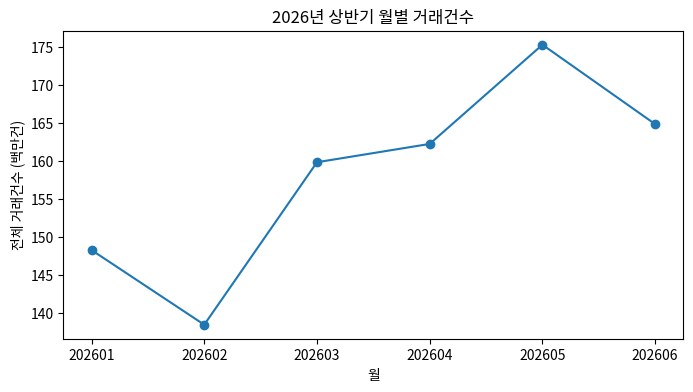

In [5]:
fig, ax = plt.subplots(figsize=(8,4))
ax.plot(monthly['STRD_YYMM'].astype(str), monthly['cnt']/1e6, marker='o')
ax.set_ylabel('전체 거래건수 (백만건)')
ax.set_xlabel('월')
ax.set_title('2026년 상반기 월별 거래건수')
plt.show()

## 2. 내국인 vs 외국인 소비구조와 TVD

In [6]:
personal = eda[eda['GENDER_CD'].isin(['1','2','3'])].copy()
personal['nat'] = np.where(personal['GENDER_CD'].eq('3'), 'foreign', 'domestic')

personal_totals = personal.groupby('GENDER_CD')[['amt','cnt']].sum()
foreign_amt_share = personal_totals.loc['3','amt']/personal_totals['amt'].sum()
foreign_cnt_share = personal_totals.loc['3','cnt']/personal_totals['cnt'].sum()
print(f'개인소비 중 외국인 금액 비중: {foreign_amt_share:.2%}')
print(f'개인소비 중 외국인 거래건수 비중: {foreign_cnt_share:.2%}')
personal_totals

개인소비 중 외국인 금액 비중: 7.90%
개인소비 중 외국인 거래건수 비중: 8.54%
Out[6]: 
                     amt        cnt
GENDER_CD                          
1          8805626620000  484721801
2          6084966970000  323656270
3          1278089570000   75509726


### TVD 정의
각 지역 $r$에서 11개 업종별 내국인 소비구성 $p_{D,rk}$과 외국인 소비구성 $p_{F,rk}$을 만든 뒤:

$$TVD_r = \frac{1}{2}\sum_k |p_{D,rk}-p_{F,rk}|$$

- 0에 가까움: 내·외국인 업종 구성이 유사
- 1에 가까움: 두 소비구조가 매우 다름
- 1/2로 나누는 이유: 두 확률분포의 L1 거리 최대값이 2이기 때문


In [7]:
rni = personal.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['amt'].sum().reset_index()
rni['share'] = rni.groupby(['region','nat'])['amt'].transform(lambda s: s/s.sum())
p = rni.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
p['abs_gap'] = (p['foreign'] - p['domestic']).abs()
tvd_amt = p.groupby('region')['abs_gap'].sum()/2

tvd_amt.describe()

Out[7]: 
count   255.000000
mean      0.185764
std       0.081587
min       0.039409
25%       0.123497
50%       0.169768
75%       0.237801
max       0.453789
Name: abs_gap, dtype: float64


In [8]:
# 건수 기준 TVD: robustness
rni_cnt = personal.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['cnt'].sum().reset_index()
rni_cnt['share'] = rni_cnt.groupby(['region','nat'])['cnt'].transform(lambda s:s/s.sum())
pc = rni_cnt.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
pc['abs_gap'] = (pc['foreign'] - pc['domestic']).abs()
tvd_cnt = pc.groupby('region')['abs_gap'].sum()/2

print('AMT-TVD vs CNT-TVD Spearman:', spearmanr(tvd_amt, tvd_cnt).statistic)

AMT-TVD vs CNT-TVD Spearman: 0.9094328971746178


## 3. Structure = Scale × TVD

Scale은 **전국 전체 거래건수에서 해당 지역이 차지하는 비중**이다. 외국인 거래만 쓰지 않는 이유는 지역 상권 자체의 활동 규모를 나타내려는 축이기 때문이다. 절대적 경제 기준이 없으므로 255개 지역의 중앙값을 상대적 임계값으로 사용한다.

In [9]:
region_cnt = eda.groupby('region')['cnt'].sum()
cnt_share = region_cnt/region_cnt.sum()
scale_thr = cnt_share.median()
tvd_thr = tvd_amt.median()
print(f'Scale median threshold = {scale_thr:.9f}')
print(f'TVD median threshold   = {tvd_thr:.9f}')

structure = pd.Series(index=tvd_amt.index, dtype=object)
structure[(cnt_share>=scale_thr)&(tvd_amt>=tvd_thr)] = '대규모·고괴리'
structure[(cnt_share>=scale_thr)&(tvd_amt<tvd_thr)] = '대규모·저괴리'
structure[(cnt_share<scale_thr)&(tvd_amt>=tvd_thr)] = '소규모·고괴리'
structure[(cnt_share<scale_thr)&(tvd_amt<tvd_thr)] = '소규모·저괴리'
structure.value_counts()

Scale median threshold = 0.003508129
TVD median threshold   = 0.169768457
Out[9]: 
대규모·저괴리    79
소규모·고괴리    79
대규모·고괴리    49
소규모·저괴리    48
Name: count, dtype: int64


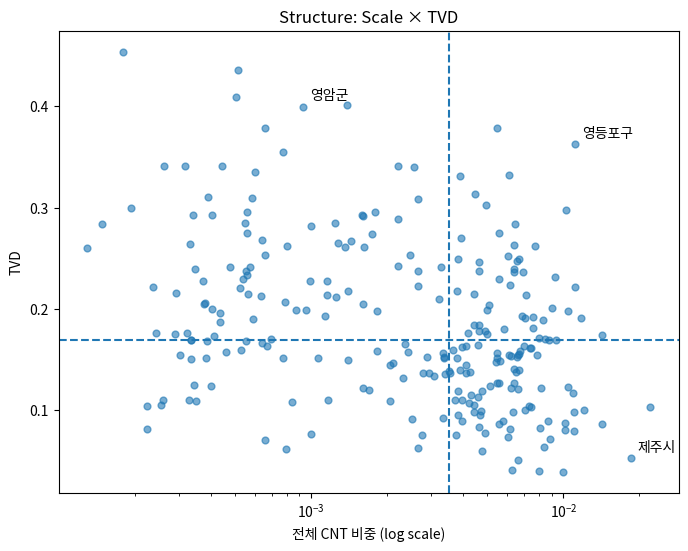

In [10]:
fig, ax = plt.subplots(figsize=(8,6))
ax.scatter(cnt_share, tvd_amt, s=24, alpha=.6)
ax.axvline(scale_thr, ls='--')
ax.axhline(tvd_thr, ls='--')
for r in ['제주특별자치도 제주시','전라남도 영암군','서울특별시 영등포구']:
    ax.annotate(r.split(' ')[-1], (cnt_share.loc[r], tvd_amt.loc[r]), xytext=(5,5), textcoords='offset points')
ax.set_xscale('log')
ax.set_xlabel('전체 CNT 비중 (log scale)')
ax.set_ylabel('TVD')
ax.set_title('Structure: Scale × TVD')
plt.show()

## 4. Structure 강건성: 기간을 반으로 나눠도 유지되는가?

In [11]:
def period_structure(months):
    x = eda[eda['STRD_YYMM'].isin(months)].copy()
    xp = x[x['GENDER_CD'].isin(['1','2','3'])].copy()
    xp['nat'] = np.where(xp['GENDER_CD'].eq('3'),'foreign','domestic')
    z = xp.groupby(['region','nat','TP_BUZ_NM_CLEAN'])['amt'].sum().reset_index()
    z['share'] = z.groupby(['region','nat'])['amt'].transform(lambda s:s/s.sum())
    q = z.pivot_table(index=['region','TP_BUZ_NM_CLEAN'], columns='nat', values='share', fill_value=0).reset_index()
    tv = q.assign(abs_gap=(q['foreign']-q['domestic']).abs()).groupby('region')['abs_gap'].sum()/2
    rc = x.groupby('region')['cnt'].sum(); cs = rc/rc.sum()
    st = pd.Series(index=tv.index, dtype=object)
    st[(cs>=scale_thr)&(tv>=tvd_thr)]='대규모·고괴리'
    st[(cs>=scale_thr)&(tv<tvd_thr)]='대규모·저괴리'
    st[(cs<scale_thr)&(tv>=tvd_thr)]='소규모·고괴리'
    st[(cs<scale_thr)&(tv<tvd_thr)]='소규모·저괴리'
    fcnt = xp[xp['nat'].eq('foreign')].groupby('region')['cnt'].sum()
    return tv, cs, st, fcnt

T1, S1, ST1, FC1 = period_structure([202601,202602,202603])
T2, S2, ST2, FC2 = period_structure([202604,202605,202606])
print('TVD H1-H2 Pearson:', pearsonr(T1,T2).statistic)
print('TVD H1-H2 Spearman:', spearmanr(T1,T2).statistic)
print('Structure 일치율:', (ST1==ST2).mean())
print('Cohen kappa:', cohen_kappa_score(ST1,ST2))

TVD H1-H2 Pearson: 0.9476181314006682
TVD H1-H2 Spearman: 0.967245397174618
Structure 일치율: 0.9215686274509803
Cohen kappa: 0.8932496075353218


In [12]:
rows=[]
for cutoff in [0,5000,10000,50000]:
    mask=(FC1>=cutoff)&(FC2>=cutoff)
    idx=mask[mask].index
    rows.append({
        '각 반기 외국인 CNT 최소':cutoff,
        '지역 수':len(idx),
        'TVD Pearson':pearsonr(T1.loc[idx],T2.loc[idx]).statistic,
        'Structure 일치율':(ST1.loc[idx]==ST2.loc[idx]).mean()
    })
pd.DataFrame(rows)

Out[12]: 
   각 반기 외국인 CNT 최소  지역 수  TVD Pearson  Structure 일치율
0                0   255     0.947618       0.921569
1             5000   249     0.981754       0.927711
2            10000   228     0.985247       0.934211
3            50000   166     0.993153       0.957831


**해석:** 전체 255개에서도 TVD와 Structure가 높은 기간 재현성을 보이고, 외국인 거래량이 충분한 지역에서는 더 안정적이다. 따라서 Structure는 비교적 안정적인 '상권 체질'로 사용하고, 최근 변화는 별도 Momentum으로 분리한다.

## 5. Momentum: CNT × ATV 최근 변화

$AMT=CNT\times ATV$이므로 금액 변화는 거래 횟수와 객단가 변화로 분해할 수 있다. 기본 창은 H1(1~3월) vs H2(4~6월)이며, 지역 변화에서 같은 기간 전국 변화를 빼 **초과 변화(excess change)**를 계산한다.

$$M^{CNT}_r=\Delta\ln(CNT_r)-\Delta\ln(CNT_{national})$$
$$M^{ATV}_r=\Delta\ln(ATV_r)-\Delta\ln(ATV_{national})$$

여기서는 상권 전체 최근 방향을 보기 때문에 법인을 포함한 전체 거래를 사용한다.

In [13]:
region_month = eda.groupby(['region','STRD_YYMM']).agg(amt=('amt','sum'),cnt=('cnt','sum')).reset_index()

def block_momentum(m1,m2):
    a=region_month[region_month['STRD_YYMM'].isin(m1)].groupby('region')[['amt','cnt']].sum()
    b=region_month[region_month['STRD_YYMM'].isin(m2)].groupby('region')[['amt','cnt']].sum()
    a['atv']=a['amt']/a['cnt']; b['atv']=b['amt']/b['cnt']
    na=region_month[region_month['STRD_YYMM'].isin(m1)][['amt','cnt']].sum()
    nb=region_month[region_month['STRD_YYMM'].isin(m2)][['amt','cnt']].sum()
    out=pd.DataFrame(index=a.index)
    out['CNT']=(np.log(b['cnt']/a['cnt'])-np.log(nb['cnt']/na['cnt']))*100
    out['ATV']=(np.log(b['atv']/a['atv'])-np.log((nb['amt']/nb['cnt'])/(na['amt']/na['cnt'])))*100
    out['AMT']=out['CNT']+out['ATV']
    return out

M3=block_momentum([202601,202602,202603],[202604,202605,202606])
M2=block_momentum([202601,202602],[202605,202606])
print('CNT 3M-2M Pearson:', pearsonr(M3['CNT'],M2['CNT']).statistic)
print('ATV 3M-2M Pearson:', pearsonr(M3['ATV'],M2['ATV']).statistic)
print('CNT/ATV 방향 모두 유지:', ((np.sign(M3['CNT'])==np.sign(M2['CNT'])) & (np.sign(M3['ATV'])==np.sign(M2['ATV']))).mean())

CNT 3M-2M Pearson: 0.9827255076054494
ATV 3M-2M Pearson: 0.9795359288978002
CNT/ATV 방향 모두 유지: 0.8823529411764706


## 6. Confidence: 기간창을 바꿔도 Momentum이 충분히 같은 방향인가?

3개월 값과 2개월 값의 차이 $D=M_{3M}-M_{2M}$의 robust scale을 $1.4826\times MAD(D)$로 계산한다.

각 축(CNT, ATV)은 다음 두 조건을 동시에 충족하면 **Stable**로 본다.
1. 3개월과 2개월 신호의 방향이 동일
2. 두 창의 신호 중 더 작은 절대값도 robust scale보다 큼

즉 단순히 부호만 같은 것이 아니라, **0 근처의 경계적 신호가 아닌지**도 확인한다.
- CNT·ATV 모두 Stable → High
- 한 축만 Stable → Medium
- 둘 다 Stable 아님 → Low


In [14]:
Dcnt=M3['CNT']-M2['CNT']; Datv=M3['ATV']-M2['ATV']
S_cnt=1.4826*np.median(np.abs(Dcnt-np.median(Dcnt)))
S_atv=1.4826*np.median(np.abs(Datv-np.median(Datv)))
stable_cnt=(np.sign(M3['CNT'])==np.sign(M2['CNT'])) & (np.minimum(np.abs(M3['CNT']),np.abs(M2['CNT']))>S_cnt)
stable_atv=(np.sign(M3['ATV'])==np.sign(M2['ATV'])) & (np.minimum(np.abs(M3['ATV']),np.abs(M2['ATV']))>S_atv)
confidence=pd.Series(np.where(stable_cnt&stable_atv,'High',np.where(stable_cnt|stable_atv,'Medium','Low')),index=M3.index)
print('robust scale CNT:',S_cnt)
print('robust scale ATV:',S_atv)
confidence.value_counts()

robust scale CNT: 2.214311511000665
robust scale ATV: 0.7727485730252659
Out[14]: 
High      119
Medium    110
Low        26
Name: count, dtype: int64


## 7. 255개 외부데이터 결합

In [15]:
moj=pd.read_csv(MOJ_PATH)
pop=pd.read_csv(POP_PATH)
print('MOJ rows:',len(moj),' / population rows:',len(pop))

foreign = personal[personal['nat'].eq('foreign')]
BCf = foreign.groupby('region').agg(BC_foreign_amt_total=('amt','sum'),BC_foreign_cnt_total=('cnt','sum'))
rg = personal.groupby(['region','nat'])['amt'].sum().unstack(fill_value=0)
foreign_share = rg['foreign']/(rg['foreign']+rg['domestic'])

core=pd.DataFrame({
    'region':tvd_amt.index,
    'cnt_share':cnt_share,
    'tvd_amt':tvd_amt,
    'structure':structure,
    'foreign_amt_share_personal':foreign_share,
}).reset_index(drop=True)
core=core.merge(BCf.reset_index(),on='region').merge(pop[['region','resident_population_202606']],on='region').merge(moj[['region','MOJ_registered_foreigners_202606']],on='region')
core['registered_foreign_share']=core['MOJ_registered_foreigners_202606']/(core['resident_population_202606']+core['MOJ_registered_foreigners_202606'])
print('최종 조인:',core.shape)
print('결측:',core.isna().sum().sum())
core.head()

MOJ rows: 255  / population rows: 255
최종 조인: (255, 10)
결측: 0
Out[15]: 
        region  cnt_share  tvd_amt structure  foreign_amt_share_personal  \
0  강원특별자치도 강릉시   0.003786 0.152142   대규모·저괴리                    0.052001   
1  강원특별자치도 고성군   0.000443 0.341093   소규모·고괴리                    0.081873   
2  강원특별자치도 동해시   0.001406 0.150027   소규모·저괴리                    0.048816   
3  강원특별자치도 삼척시   0.000642 0.166922   소규모·저괴리                    0.046824   
4  강원특별자치도 속초시   0.002429 0.158036   소규모·저괴리                    0.052359   

   BC_foreign_amt_total  BC_foreign_cnt_total  resident_population_202606  \
0            4200020000                224659                      205666   
1             695930000                 67590                       27204   
2            1436770000                 66023                       85589   
3             665980000                 31138                       60294   
4            3081270000                147350                       78893   

   MOJ_re

## 8. 외부검증 A: BC 외국인 소비규모가 실제 등록외국인 분포와 수렴하는가?

In [16]:
x=np.log1p(core['MOJ_registered_foreigners_202606'])
y_amt=np.log1p(core['BC_foreign_amt_total'])
y_cnt=np.log1p(core['BC_foreign_cnt_total'])
print('AMT Pearson / Spearman:', pearsonr(y_amt,x).statistic, spearmanr(y_amt,x).statistic)
print('CNT Pearson / Spearman:', pearsonr(y_cnt,x).statistic, spearmanr(y_cnt,x).statistic)
model=sm.OLS(y_amt,sm.add_constant(x)).fit()
print('AMT regression R²:',model.rsquared)

AMT Pearson / Spearman: 0.8751688870876112 0.8845708830971676
CNT Pearson / Spearman: 0.8821514104896784 0.8965092869833746
AMT regression R²: 0.7659205809261682


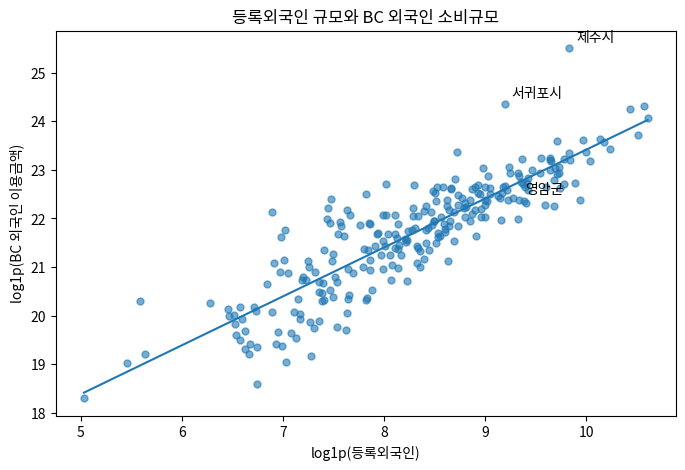

In [17]:
fig, ax=plt.subplots(figsize=(8,5))
ax.scatter(x,y_amt,s=25,alpha=.6)
xx=np.linspace(x.min(),x.max(),100)
ax.plot(xx,model.params.iloc[0]+model.params.iloc[1]*xx)
for r in ['제주특별자치도 제주시','제주특별자치도 서귀포시','전라남도 영암군']:
    row=core[core['region']==r].iloc[0]
    ax.annotate(r.split(' ')[-1],(np.log1p(row['MOJ_registered_foreigners_202606']),np.log1p(row['BC_foreign_amt_total'])),xytext=(5,5),textcoords='offset points')
ax.set_xlabel('log1p(등록외국인)')
ax.set_ylabel('log1p(BC 외국인 이용금액)')
ax.set_title('등록외국인 규모와 BC 외국인 소비규모')
plt.show()

## 9. 외부검증 B: TVD와 등록기반 외국인 비율 — 전체 255개

In [18]:
pr=pearsonr(core['tvd_amt'],core['registered_foreign_share'])
sr=spearmanr(core['tvd_amt'],core['registered_foreign_share'])
print(f'Pearson r={pr.statistic:.3f}, p={pr.pvalue:.3e}')
print(f'Spearman rho={sr.statistic:.3f}, p={sr.pvalue:.3e}')

Pearson r=0.659, p=4.270e-33
Spearman rho=0.714, p=5.330e-41


In [19]:
# bootstrap 95% CI
rng=np.random.default_rng(42)
a=core[['tvd_amt','registered_foreign_share']].to_numpy()
bp=[]; bs=[]
for _ in range(5000):
    ii=rng.integers(0,len(a),len(a))
    xx,yy=a[ii,0],a[ii,1]
    bp.append(np.corrcoef(xx,yy)[0,1])
    bs.append(spearmanr(xx,yy).statistic)
print('Pearson 95% CI:',np.quantile(bp,[.025,.975]))
print('Spearman 95% CI:',np.quantile(bs,[.025,.975]))

Pearson 95% CI: [0.59418101 0.72201986]
Spearman 95% CI: [0.64420988 0.77214778]


Spearman이 Pearson보다 높다는 것은 **TVD가 높을수록 외국인 비율도 높아지는 순위적·단조 경향이 선형관계보다 더 강하다**는 의미다. 외국인 비율의 극단값/비선형성을 고려하면 Spearman을 주지표, Pearson을 보조지표로 보는 것이 자연스럽다.

In [20]:
q33,q67=core['tvd_amt'].quantile([1/3,2/3])
core['tvd_tertile']=pd.cut(core['tvd_amt'],[-np.inf,q33,q67,np.inf],labels=['Low','Mid','High'],include_lowest=True)
tert=core.groupby('tvd_tertile',observed=True)['registered_foreign_share'].agg(['count','median','mean'])
print('TVD 33.3% / 66.7% thresholds:',q33,q67)
tert.assign(median_pct=tert['median']*100,mean_pct=tert['mean']*100)

TVD 33.3% / 66.7% thresholds: 0.14628712438215796 0.21443130371565225
Out[20]: 
             count   median     mean  median_pct  mean_pct
tvd_tertile                                               
Low             85 0.015805 0.019471    1.580470  1.947132
Mid             85 0.028253 0.031611    2.825302  3.161086
High            85 0.048110 0.055228    4.810992  5.522772


In [21]:
low=core[core['tvd_amt']<tvd_thr]['registered_foreign_share']
high=core[core['tvd_amt']>=tvd_thr]['registered_foreign_share']
u=mannwhitneyu(low,high,alternative='two-sided')
print(f'저괴리 중앙값: {low.median():.2%}')
print(f'고괴리 중앙값: {high.median():.2%}')
print(f'중앙값 배수: {high.median()/low.median():.2f}x')
print(f'Mann–Whitney p={u.pvalue:.3e}')

저괴리 중앙값: 1.97%
고괴리 중앙값: 4.28%
중앙값 배수: 2.17x
Mann–Whitney p=4.434e-24


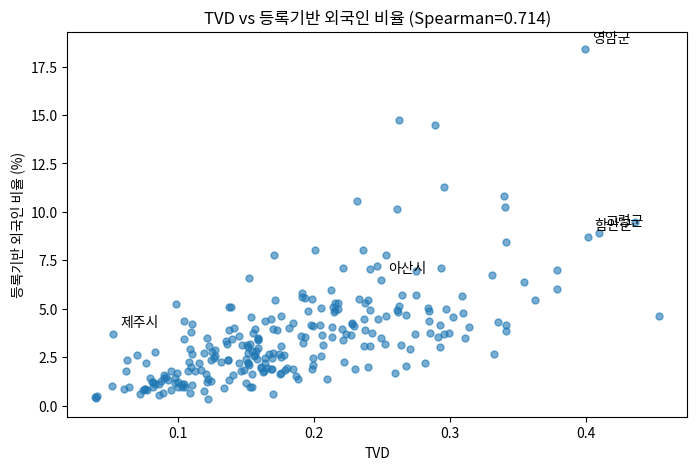

In [22]:
fig, ax=plt.subplots(figsize=(8,5))
ax.scatter(core['tvd_amt'],core['registered_foreign_share']*100,s=25,alpha=.6)
for r in ['제주특별자치도 제주시','전라남도 영암군','경상북도 고령군','경상남도 함안군','충청남도 아산시']:
    row=core[core['region']==r].iloc[0]
    ax.annotate(r.split(' ')[-1],(row['tvd_amt'],row['registered_foreign_share']*100),xytext=(5,5),textcoords='offset points')
ax.set_xlabel('TVD')
ax.set_ylabel('등록기반 외국인 비율 (%)')
ax.set_title(f'TVD vs 등록기반 외국인 비율 (Spearman={sr.statistic:.3f})')
plt.show()

## 10. 대표사례: 같은 외국인 소비 핵심지역도 구조는 다르다

In [23]:
case_regions=['제주특별자치도 제주시','제주특별자치도 서귀포시','전라남도 영암군','경상북도 고령군','경상남도 함안군','충청남도 아산시']
case=core[core['region'].isin(case_regions)][['region','structure','foreign_amt_share_personal','tvd_amt','resident_population_202606','MOJ_registered_foreigners_202606','registered_foreign_share']].copy()
case['foreign_amt_share_personal']*=100
case['registered_foreign_share']*=100
case.sort_values('tvd_amt')

Out[23]: 
           region structure  foreign_amt_share_personal  tvd_amt  \
224   제주특별자치도 제주시   대규모·저괴리                   36.380760 0.052582   
223  제주특별자치도 서귀포시   대규모·저괴리                   29.693743 0.098454   
234      충청남도 아산시   대규모·고괴리                   16.602717 0.249442   
200      전라남도 영암군   소규모·고괴리                   32.179733 0.399595   
84       경상남도 함안군   소규모·고괴리                   12.286506 0.401225   
89       경상북도 고령군   소규모·고괴리                   18.746079 0.409393   

     resident_population_202606  MOJ_registered_foreigners_202606  \
224                      484123                             18638   
223                      178669                              9838   
234                      363678                             25268   
200                       50076                             11288   
84                        56867                              5435   
89                        29545                              2894   

     registered_foreign_share

- 제주시: 외국인 소비비중은 매우 높지만 TVD는 낮고 등록기반 외국인 비율도 영암보다 훨씬 낮다. **방문/유입 수요가 섞였을 가능성**과 정합적이지만, 관광객 데이터 없이 원인을 확정하지 않는다.
- 영암군: 외국인 소비비중도 높고 TVD·등록기반 외국인 비율도 매우 높다. **정주 외국인 생활수요와의 연관성**이 상대적으로 강한 사례다.
- 따라서 `외국인이 많이 쓰는 곳` 하나의 라벨로 묶기보다, 소비구조를 분리해야 한다.

## 11. 잔차 분석: 등록외국인 수로 설명되지 않는 외국인 카드소비

In [24]:
resid=(model.resid-model.resid.mean())/model.resid.std(ddof=1)
core['std_residual']=resid.values
print('양(+) 잔차 상위')
display(core.nlargest(8,'std_residual')[['region','MOJ_registered_foreigners_202606','foreign_amt_share_personal','tvd_amt','std_residual']])
print('음(-) 잔차 하위')
display(core.nsmallest(5,'std_residual')[['region','MOJ_registered_foreigners_202606','foreign_amt_share_personal','tvd_amt','std_residual']])

양(+) 잔차 상위
음(-) 잔차 하위


,region,MOJ_registered_foreigners_202606,foreign_amt_share_personal,tvd_amt,std_residual
224,제주특별자치도 제주시,18638,0.363808,0.052582,3.910547
123,대구광역시 중구,986,0.047249,0.154846,3.189047
223,제주특별자치도 서귀포시,9838,0.296937,0.098454,3.026684
122,대구광역시 수성구,1764,0.035770,0.039409,2.626793
250,충청북도 청주시 상당구,1703,0.090027,0.075868,2.398829
134,부산광역시 동래구,1119,0.022679,0.039988,2.333183
22,경기도 과천시,266,0.031541,0.122125,2.294422
114,광주광역시 서구,3034,0.058402,0.082872,2.236471


,region,MOJ_registered_foreigners_202606,foreign_amt_share_personal,tvd_amt,std_residual
98,경상북도 영양군,848,0.059220,0.283688,-2.672140
9,강원특별자치도 인제군,1448,0.032884,0.168563,-2.602265
222,전북특별자치도 진안군,1128,0.045681,0.104237,-2.400941
11,강원특별자치도 철원군,2041,0.038648,0.195700,-2.299528
49,경기도 연천군,1863,0.046741,0.292681,-2.034460


잔차는 원인 그 자체가 아니다. 양(+) 잔차는 등록외국인 규모보다 카드소비가 많은 지역이고, 관광·통근·쇼핑 유입 등 외부 수요 가설을 추가 검증할 후보가 된다. 음(-) 잔차는 역외소비, 현금/타카드 결제, 가맹점 커버리지 등의 가능성을 점검할 후보가 된다.

## 12. 한국관광공사 2026H1 방문자 데이터와 External Context

BC 카드 데이터와 기간을 정확히 맞추기 위해 한국관광공사 `지역별 방문자수` OpenAPI의 **2026-01-01~2026-06-30** 일별 데이터를 결합한다.

- `touDivCd=1`: 현지인(a)
- `touDivCd=2`: 외지인(b)
- `touDivCd=3`: 외국인(c)

이 분석에서 외국인 방문 비중은 **외부 방문자 중 외국인 비중**으로 정의한다.

\[
ForeignVisitShare_r=\frac{Foreign_r}{OutOfTown_r+Foreign_r}
\]

초기 요약파일처럼 현지인을 분모에 넣지 않는다. 이동통신상 '방문자'는 방문 목적을 직접 식별하지 않으므로 최종 라벨은 '관광형'이 아니라 **방문우세형**으로 표현한다.

In [25]:
# KTO 2026H1 raw load & correct foreign visit share
kto = pd.read_csv(KTO_RAW_PATH, dtype={'signguCode':str,'touDivCd':str,'baseYmd':str})
kto['touDivCd'] = kto['touDivCd'].str.replace('.0','',regex=False)

sido_map = {
    '11':'서울특별시','26':'부산광역시','27':'대구광역시','28':'인천광역시',
    '29':'광주광역시','30':'대전광역시','31':'울산광역시','36':'세종특별자치시',
    '41':'경기도','43':'충청북도','44':'충청남도','46':'전라남도','47':'경상북도',
    '48':'경상남도','50':'제주특별자치도','51':'강원특별자치도','52':'전북특별자치도'
}
kto['SIDO_NM'] = kto['signguCode'].str[:2].map(sido_map)

kagg = (kto[kto['touDivCd'].isin(['2','3'])]
        .groupby(['SIDO_NM','signguCode','signguNm','touDivCd'],as_index=False)['touNum'].sum())
kp = (kagg.pivot_table(index=['SIDO_NM','signguCode','signguNm'], columns='touDivCd', values='touNum', fill_value=0)
      .reset_index())
kp.columns.name = None
kp = kp.rename(columns={'signguNm':'CCG_NM','2':'kto_out_of_town_total','3':'kto_foreign_total'})
kp['kto_foreign_visit_share'] = kp['kto_foreign_total']/(kp['kto_foreign_total']+kp['kto_out_of_town_total'])

obs = (kto[kto['touDivCd'].eq('3')]
       .groupby(['SIDO_NM','signguCode','signguNm'])['baseYmd'].nunique()
       .reset_index(name='kto_foreign_observed_days')
       .rename(columns={'signguNm':'CCG_NM'}))
kp = kp.merge(obs,on=['SIDO_NM','signguCode','CCG_NM'],how='left')
print('KTO raw rows:', len(kto))
print('KTO date range:', kto['baseYmd'].min(), '~', kto['baseYmd'].max())
print(kp['kto_foreign_observed_days'].value_counts().sort_index())
kp.head()

KTO raw rows: 145152
KTO date range: 20260101 ~ 20260630
kto_foreign_observed_days
150      4
181    264
Name: count, dtype: int64
Out[25]: 
   SIDO_NM signguCode CCG_NM  kto_out_of_town_total  kto_foreign_total  \
0  강원특별자치도      51110    춘천시      14,525,024.500000     536,202.330000   
1  강원특별자치도      51130    원주시      17,060,893.500000     180,404.400000   
2  강원특별자치도      51150    강릉시      16,798,516.000000     205,463.510000   
3  강원특별자치도      51170    동해시       6,278,695.500000      74,553.580000   
4  강원특별자치도      51190    태백시       2,498,100.500000      27,779.290000   

   kto_foreign_visit_share  kto_foreign_observed_days  
0                 0.035602                        181  
1                 0.010464                        181  
2                 0.012083                        181  
3                 0.011735                        181  
4                 0.010998                        181  


### 12.1 BC 255개 지역과 결합 및 엄격표본

KTO 지역명과 BC 지역명을 `SIDO_NM + CCG_NM`으로 결합한다. 255개가 모두 매칭되지만, 화성시 4개 신설구는 KTO 데이터가 150일만 존재한다. 본검증은 181일이 모두 관측된 **251개 지역**으로 수행하고, 4개 지역은 별도 민감도 대상으로 남긴다.

In [26]:
external_full = pd.read_csv(EXT_JOINED_PATH)
context = external_full.merge(
    kp[['SIDO_NM','CCG_NM','signguCode','kto_out_of_town_total','kto_foreign_total','kto_foreign_visit_share','kto_foreign_observed_days']],
    on=['SIDO_NM','CCG_NM'], how='left', validate='1:1'
)
print('BC regions:', len(context))
print('KTO matched:', context['kto_foreign_visit_share'].notna().sum())
print(context['kto_foreign_observed_days'].value_counts().sort_index())
strict = context[context['kto_foreign_observed_days'].eq(181)].copy()
print('strict N:', len(strict))

BC regions: 255
KTO matched: 255
kto_foreign_observed_days
150      4
181    251
Name: count, dtype: int64
strict N: 251


### 12.2 ContextGap 정의

절대 방문량 자체가 아니라 **정주집중도와 방문집중도의 상대적 불균형**을 비교한다.

\[
ContextGap_r=Pctl(ForeignVisitShare_r)-Pctl(RegisteredForeignShare_r)
\]

- 값이 크면: 등록외국인에 비해 외국인 방문 존재감이 큼 → 방문우세
- 값이 작으면: 방문보다 등록외국인 집중도가 큼 → 정주우세
- 중간이면: 혼합형

In [27]:
strict['visitor_pctile'] = strict['kto_foreign_visit_share'].rank(method='average',pct=True)*100
strict['resident_pctile'] = strict['registered_foreign_share'].rank(method='average',pct=True)*100
strict['context_gap'] = strict['visitor_pctile'] - strict['resident_pctile']

# 등록외국인 규모만으로 설명되는 BC 외국인 소비 기대값의 잔차
X = sm.add_constant(np.log1p(strict['MOJ_registered_foreigners_202606']))
y = np.log1p(strict['BC_foreign_amt_total'])
base_spend_model = sm.OLS(y, X).fit()
strict['bc_spend_residual'] = base_spend_model.resid

print('base model R2:', round(base_spend_model.rsquared,4))
print('ContextGap vs BC residual')
print(' Pearson:', pearsonr(strict['context_gap'],strict['bc_spend_residual']))
print(' Spearman:', spearmanr(strict['context_gap'],strict['bc_spend_residual']))
print('ContextGap vs TVD')
print(' Pearson:', pearsonr(strict['context_gap'],strict['tvd_amt']))
print(' Spearman:', spearmanr(strict['context_gap'],strict['tvd_amt']))
print('Raw visit share vs BC residual')
print(' Pearson:', pearsonr(strict['kto_foreign_visit_share'],strict['bc_spend_residual']))

base model R2: 0.7624
ContextGap vs BC residual
 Pearson: PearsonRResult(statistic=np.float64(0.3629522448840826), pvalue=np.float64(3.1265418408793626e-09))
 Spearman: SignificanceResult(statistic=np.float64(0.3691755640106738), pvalue=np.float64(1.5980568481186151e-09))
ContextGap vs TVD
 Pearson: PearsonRResult(statistic=np.float64(-0.37848860140520146), pvalue=np.float64(5.697204657375256e-10))
 Spearman: SignificanceResult(statistic=np.float64(-0.4018003548229578), pvalue=np.float64(3.7204912920413196e-11))
Raw visit share vs BC residual
 Pearson: PearsonRResult(statistic=np.float64(0.01059959573032677), pvalue=np.float64(0.8672947897120437))


### 핵심 해석

2026H1로 기간을 완전히 맞춘 뒤에도 `ContextGap`은 BC 외국인 소비잔차와 유의한 양(+)의 관계를 보이고, TVD와는 유의한 음(-)의 관계를 보인다. 반면 외국인 방문비중 자체와 BC 소비잔차의 Pearson 상관은 사실상 0이다.

따라서 **'외국인이 많이 방문하면 BC 소비가 크다'**가 아니라, **'정주 외국인 집중도 대비 방문 외국인 집중도가 얼마나 높은가'**라는 상대적 Context가 소비패턴과 연결된다고 해석한다.

In [28]:
q33, q67 = strict['context_gap'].quantile([1/3,2/3])
strict['external_context'] = pd.cut(
    strict['context_gap'], [-np.inf,q33,q67,np.inf],
    labels=['정주우세형','혼합형','방문우세형'], include_lowest=True
)
summary_context = strict.groupby('external_context', observed=False).agg(
    n=('region','size'),
    visit_share_median=('kto_foreign_visit_share','median'),
    resident_share_median=('registered_foreign_share','median'),
    bc_residual_median=('bc_spend_residual','median'),
    tvd_median=('tvd_amt','median')
)
print('Q33=',q33,'Q67=',q67)
display(summary_context)
print('Kruskal BC residual:', kruskal(*[g['bc_spend_residual'] for _,g in strict.groupby('external_context',observed=False)]))
print('Kruskal TVD:', kruskal(*[g['tvd_amt'] for _,g in strict.groupby('external_context',observed=False)]))

Q33= -15.53784860557769 Q67= 7.436918990703839
Kruskal BC residual: KruskalResult(statistic=np.float64(29.090831684599493), pvalue=np.float64(4.819546365821254e-07))
Kruskal TVD: KruskalResult(statistic=np.float64(33.691659284235584), pvalue=np.float64(4.830022383093407e-08))


,n,visit_share_median,resident_share_median,bc_residual_median,tvd_median
external_context,,,,,
정주우세형,84,0.012102,0.042292,-0.219473,0.214995
혼합형,83,0.013358,0.027327,0.040962,0.164034
방문우세형,84,0.025459,0.021126,0.149551,0.144023


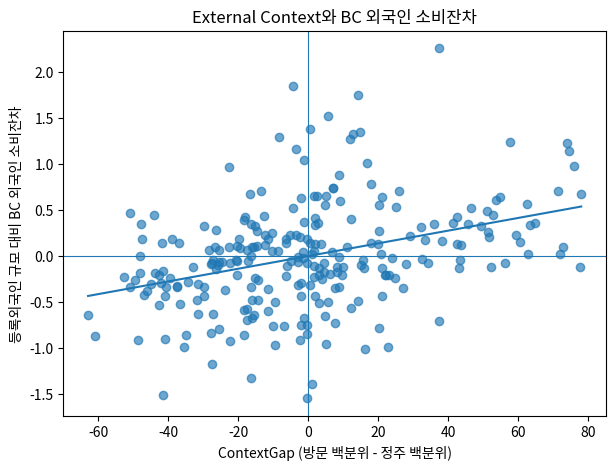

In [29]:
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(strict['context_gap'], strict['bc_spend_residual'], alpha=.65)
coef = np.polyfit(strict['context_gap'], strict['bc_spend_residual'], 1)
xx = np.linspace(strict['context_gap'].min(), strict['context_gap'].max(), 100)
ax.plot(xx, coef[0]*xx+coef[1])
ax.axhline(0, linewidth=.8)
ax.axvline(0, linewidth=.8)
ax.set_xlabel('ContextGap (방문 백분위 - 정주 백분위)')
ax.set_ylabel('등록외국인 규모 대비 BC 외국인 소비잔차')
ax.set_title('External Context와 BC 외국인 소비잔차')
plt.show()

### 12.3 대표사례: 제주 vs 영암

같은 '외국인 소비가 중요한 지역'이라도 외부 방문수요와 정주수요의 성격이 다를 수 있다. 제주시는 방문우세형, 영암군은 정주우세형으로 분리된다. 강남·해운대는 강한 방문우세, 거제는 외국인 방문과 정주가 모두 높은 혼합형 사례다.

In [30]:
cases = ['제주특별자치도 제주시','전라남도 영암군','서울특별시 강남구','부산광역시 해운대구','경상남도 거제시']
strict[strict['region'].isin(cases)][[
    'region','kto_foreign_visit_share','visitor_pctile','registered_foreign_share','resident_pctile',
    'context_gap','external_context','tvd_amt','bc_spend_residual'
]].sort_values('context_gap',ascending=False)

Out[30]: 
          region  kto_foreign_visit_share  visitor_pctile  \
144   부산광역시 해운대구                 0.078586       92.828685   
145    서울특별시 강남구                 0.042790       85.258964   
224  제주특별자치도 제주시                 0.184557       98.804781   
65      경상남도 거제시                 0.092249       94.820717   
200     전라남도 영암군                 0.028351       76.095618   

     registered_foreign_share  resident_pctile  context_gap external_context  \
144                  0.012889        14.741036    78.087649            방문우세형   
145                  0.011025        11.155378    74.103586            방문우세형   
224                  0.037071        61.354582    37.450199            방문우세형   
65                   0.067464        91.633466     3.187251              혼합형   
200                  0.183952       100.000000   -23.904382            정주우세형   

     tvd_amt  bc_spend_residual  
144 0.087737           0.669526  
145 0.102905           1.230024  
224 0.052582           2.256214  
65  0.

## 13. 최종 Action Matrix 생성

In [31]:
action=pd.DataFrame(index=tvd_amt.index)
action['structure']=structure
action['cnt_share']=cnt_share
action['tvd_amt']=tvd_amt
action['foreign_amt_share_personal']=foreign_share
action['momentum_cnt']=M3['CNT']
action['momentum_atv']=M3['ATV']
action['confidence']=confidence

def sig(r):
    c=M3.loc[r,'CNT']; a=M3.loc[r,'ATV']
    if c>0 and a>0:return '거래·객단가 동반 상승'
    if c>0:return '거래 확대'
    if a>0:return '객단가 상승'
    return '동반 약화'
action['momentum_signal']=[sig(r) for r in action.index]
action.reset_index(names='region').head(10)

Out[31]: 
        region structure  cnt_share  tvd_amt  foreign_amt_share_personal  \
0  강원특별자치도 강릉시   대규모·저괴리   0.003786 0.152142                    0.052001   
1  강원특별자치도 고성군   소규모·고괴리   0.000443 0.341093                    0.081873   
2  강원특별자치도 동해시   소규모·저괴리   0.001406 0.150027                    0.048816   
3  강원특별자치도 삼척시   소규모·저괴리   0.000642 0.166922                    0.046824   
4  강원특별자치도 속초시   소규모·저괴리   0.002429 0.158036                    0.052359   
5  강원특별자치도 양구군   소규모·고괴리   0.000243 0.176053                    0.094434   
6  강원특별자치도 양양군   소규모·저괴리   0.000551 0.168776                    0.047848   
7  강원특별자치도 영월군   소규모·고괴리   0.000347 0.239894                    0.065388   
8  강원특별자치도 원주시   대규모·저괴리   0.005783 0.089870                    0.065569   
9  강원특별자치도 인제군   소규모·저괴리   0.000386 0.168563                    0.032884   

   momentum_cnt  momentum_atv confidence momentum_signal  
0     -1.779348      0.056274        Low          객단가 상승  
1     22.063079      4.582902      

### 지표 역할 분리

- **Structure** → 어떤 상권인가? (`Scale × TVD`)
- **Momentum** → 최근 어느 방향으로 움직이는가? (`CNT × ATV`)
- **Confidence** → 그 최근 신호를 얼마나 강하게 믿을 수 있는가?
- **External Context** → 정주·방문·관광 등 어떤 외부 맥락과 정합적인가?
- **Action** → 이해관계자별로 무엇을 할 것인가?


## 14. LLM Action Layer 제안

LLM은 숫자 계산이나 지역 유형 판정을 대신하지 않는다. 분석 엔진이 먼저 확정한 구조화된 진단 패킷을 입력으로 받는다.

`Raw Data → Analytics Engine → Labels → Rule Layer → Evidence Layer → LLM → Stakeholder Action`

권장 이해관계자:
1. BC카드 — 타겟 프로모션, 가맹점 발굴, 상권 세그먼트 상품화
2. 소상공인/창업자 — 부족 업종, 고객구성, 입지·상품 전략
3. 지자체 — 정주우세·혼합·방문우세 맥락(12장 External Context)에 따른 상권지원·생활서비스 전략

Evidence Layer에는 `출처 / 사실 / 적용조건 / 지원 가능한 Action / 적용 제외조건 / 근거등급 / 기준시점`을 저장하고, LLM이 KB에 없는 전략을 자유롭게 발명하지 못하도록 제한하는 것이 핵심이다.

In [32]:
# 예시: LLM에 넘길 제주 진단 패킷
r='제주특별자치도 제주시'
row=core[core['region']==r].iloc[0]
crow=strict[strict['region']==r].iloc[0]   # 12장에서 판정한 External Context
packet={
    'region':r,
    'structure':structure.loc[r],
    'tvd':round(float(tvd_amt.loc[r]),3),
    'scale_share':round(float(cnt_share.loc[r]),6),
    'foreign_amt_share':round(float(foreign_share.loc[r]),3),
    'momentum_cnt':round(float(M3.loc[r,'CNT']),2),
    'momentum_atv':round(float(M3.loc[r,'ATV']),2),
    'confidence':confidence.loc[r],
    'registered_foreign_share':round(float(row['registered_foreign_share']),4),
    # 12장 External Context 판정 결과 (KTO 2026H1 + 등록외국인 비율, 엄격표본 기준)
    'foreign_visit_share':round(float(crow['kto_foreign_visit_share']),4),
    'visitor_pctile':round(float(crow['visitor_pctile']),1),
    'resident_pctile':round(float(crow['resident_pctile']),1),
    'context_gap':round(float(crow['context_gap']),2),
    'external_context':str(crow['external_context']),
}
packet

Out[32]: 
{'region': '제주특별자치도 제주시',
 'structure': '대규모·저괴리',
 'tvd': 0.053,
 'scale_share': 0.018493,
 'foreign_amt_share': 0.364,
 'momentum_cnt': 4.01,
 'momentum_atv': -0.23,
 'confidence': 'Medium',
 'registered_foreign_share': 0.0371,
 'foreign_visit_share': 0.1846,
 'visitor_pctile': 98.8,
 'resident_pctile': 61.4,
 'context_gap': 37.45,
 'external_context': '방문우세형'}


## 15. 최종 의사결정 프레임워크

최종 제품 구조는 다음과 같다.

`Structure (Scale + TVD)` → `Momentum` → `Confidence` → `External Context` → `LLM Action`

- **Structure**: 현재 시장의 규모와 내·외국인 소비구조 차이
- **Momentum**: 최근 거래건수·객단가의 방향
- **Confidence**: 기간창 변경에도 Momentum이 유지되는지
- **External Context**: 정주 외국인 대비 외부 방문 외국인 수요의 상대적 우세
- **LLM Action**: 검증된 진단패킷과 근거카드를 바탕으로 이해관계자별 실행안을 생성

LLM은 정량 진단을 새로 계산하거나 임의로 라벨을 생성하지 않고, 분석엔진에서 확정된 지표와 외부 근거를 설명·행동안으로 변환하는 역할만 맡는다.

## 16. 최종 결론

1. 단순 외국인 소비액/비중 순위만으로는 서로 다른 상권을 같은 유형으로 묶을 위험이 있다.  
2. TVD는 `내국인과 외국인이 무엇을 다르게 소비하는가`를 측정하며, Structure의 두 번째 축으로 안정적으로 작동한다.  
3. Structure는 H1/H2 일치율 92.2%, κ=0.893으로 강건하다.  
4. Momentum은 3개월/2개월 창에서 CNT r≈0.983, ATV r≈0.980으로 전체적인 강건성이 확인되며, Confidence로 민감 지역을 별도 표시한다.  
5. 255개 전체 외부검증에서 TVD와 등록기반 외국인 비율은 Pearson r≈0.659, Spearman ρ≈0.714로 유의한 양(+) 관계를 보였다.  
6. TVD 삼분위별 등록기반 외국인 비율 중앙값은 약 **1.58% → 2.83% → 4.81%**로 단계적으로 증가한다.  
7. 한국관광공사 2026H1 방문자 데이터를 결합한 External Context에서 ContextGap(외국인 방문비중 백분위 − 등록외국인 비율 백분위)은 등록외국인 규모로 설명되지 않는 BC 외국인 소비잔차와 양(+)의 관계(Pearson r≈0.363, Spearman ρ≈0.369), TVD와 음(−)의 관계(r≈−0.378, ρ≈−0.402)를 보였다. 정주우세→혼합→방문우세로 갈수록 TVD 중앙값은 **0.215 → 0.164 → 0.144**로 낮아진다. 반면 외국인 방문비중 단독과 소비잔차의 상관은 r≈0.011로 사실상 0이어서, ‘많이 방문하는 곳’이 아니라 **정주 대비 방문이 상대적으로 우세한 곳**이 소비패턴과 연결된다.  
8. 최종 제품은 `Ranking`이 아니라 **Diagnosis → Action**으로 포지셔닝하며, LLM은 검증된 진단과 Evidence KB를 이해관계자별 액션으로 번역하는 역할에 한정한다.

> 상관은 인과가 아니다. 한국관광공사 방문자 데이터를 결합해 정주우세·혼합·방문우세 맥락은 데이터로 구분했지만, 이는 관찰자료의 관계이므로 방문 수요가 소비패턴의 원인이라고 확정할 수는 없다. 또한 이동통신 기반 ‘방문자’는 방문 목적을 식별하지 않으므로 관광 수요로 단정하지 않고 ‘방문우세형’으로 표현한다. 인과 효과는 파일럿 운영 전후 비교 등으로 추가 검증해야 한다.
